# Лабораторная работа №3: Foundation models для сегментации: SAM/SAM 2

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Получить маски по point и box prompts.
- Автоматически сформировать prompts из GT или детектора.
- Сравнить zero-shot и refinement head.


## Теоретическая часть

Promptable segmentation оценивает маску $M=f(I,p)$ по изображению и prompt $p$ (точка, box или маска). SAM разделяет тяжёлый image encoder и лёгкий prompt/mask decoder, поэтому один embedding изображения можно использовать для многих запросов.

![SAM architecture](https://raw.githubusercontent.com/facebookresearch/segment-anything/main/assets/model_diagram.png)


### Математическая постановка

Качество promptable-модели оценивают не только IoU, но и числом взаимодействий до достижения целевого качества: $N@IoU\geq\tau$. Для ускорения разметки важна доля масок, принимаемых без существенной коррекции.


### Материалы

- [Segment Anything](https://github.com/facebookresearch/segment-anything)
- [Transformers SAM docs](https://huggingface.co/docs/transformers/model_doc/sam)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Получить маски по point и box prompts.
2. Автоматически сформировать prompts из GT или детектора.
3. Сравнить zero-shot и refinement head.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** SAM ViT-B/MobileSAM inference, frozen encoder.
- **Ограничение данных:** до 200 изображений 512 px.
- **Fallback:** CPU на 20 изображениях или MobileSAM.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
# Отдельная подпапка: в artifacts/ лежат результаты лабораторной №1, в artifacts/lab2 — лабораторной №2.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab3"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT), "artifacts": str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data', 'artifacts': 'artifacts\\lab3'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Задание 1. Загрузка SAM и отложенных масок

*Вес: 1 балл.*

**Постановка.** Сравнение prompts возможно лишь на одних размеченных изображениях.

Выполните следующие действия:
1. Загрузите pretrained SAM и test Oxford-IIIT Pet.
2. Зафиксируйте индексы проверки.

**Результат.** dataset_manifest.json и объекты processor, model, eval_ds.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


SAM (Segment Anything Model) — это нейросеть от Meta для сегментации, то есть для выделения объекта на картинке попиксельно. Обычная сегментационная модель сама ищет заранее заданные классы, например «кошка» или «собака». SAM работает иначе: ты показываешь, что выделить, а модель строит маску этого объекта. Подсказка (prompt) может быть точкой на объекте или рамкой вокруг него.

У модели три части:
1. Image encoder — тяжёлая часть, один раз переводит картинку в числовое представление (embedding).
2. Prompt encoder — кодирует подсказку.
3. Mask decoder — лёгкая часть, по embedding и подсказке быстро выдаёт маску. Поэтому одну картинку можно быстро проверять с разными подсказками.

Модель обучена заранее на огромном наборе масок разных объектов, её часто называют foundation model. Слово pretrained означает, что мы скачиваем готовые веса (facebook/sam-vit-base) и не обучаем её. На питомцах она не дообучалась, поэтому в задании такой режим называется zero-shot.

In [3]:
import torchvision, transformers
from PIL import Image
from scipy import ndimage
from torch.utils.data import Dataset
from torchvision.datasets import OxfordIIITPet
from transformers import SamModel, SamProcessor

SAM_CHECKPOINT = "facebook/sam-vit-base"
N_EVAL = 8 if FAST_DEV_RUN else 200  # профиль вычислений: до 200 изображений
MAX_SIDE = 512                       # и не более 512 px по длинной стороне


def object_mask(trimap):
    """Trimap Oxford-IIIT Pet (1 — питомец, 2 — фон, 3 — граница) -> бинарная маска объекта bool [H, W].

    Объект — всё, кроме фона: пограничная лента относится к контуру питомца.
    В части trimap есть посторонние линии класса «граница» по краям кадра, не связанные с питомцем.
    Они отбрасываются: остаются только связные области, содержащие пиксели питомца. Иначе
    box по такой маске растягивается на весь кадр и перестаёт указывать на объект.
    """
    trimap = np.array(trimap)
    obj = trimap != 2
    labels, n = ndimage.label(obj, structure=np.ones((3, 3), dtype=bool))
    if n > 1:
        keep = np.unique(labels[trimap == 1])
        if len(keep):  # если пикселей питомца нет вовсе, маска остаётся как есть
            obj = np.isin(labels, keep)
    return obj


class PetMasks(Dataset):
    """Фиксированная подвыборка Oxford-IIIT Pet: RGB-изображение (PIL) и бинарная маска объекта того же размера."""

    def __init__(self, base, indices):
        self.base, self.indices = base, list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, trimap = self.base[self.indices[i]]
        image = image.convert("RGB")
        scale = MAX_SIDE / max(image.size)
        if scale < 1:  # изображение — билинейно, маска — только NEAREST: метки классов нельзя усреднять
            size = (round(image.width * scale), round(image.height * scale))
            image, trimap = image.resize(size, Image.BILINEAR), trimap.resize(size, Image.NEAREST)
        return image, object_mask(trimap)


# Отложенные данные — официальный раздел test: с trainval, на котором дальше обучаются baseline и корректор, он не пересекается.
test_base = OxfordIIITPet(root=str(DATA_ROOT), split="test", target_types="segmentation", download=True)

# Индексы проверки фиксируются seed. Изображения с вырожденной разметкой (нет объекта или нет фона)
# пропускаются: из такой маски нельзя получить ни box, ни точку.
perm = torch.randperm(len(test_base), generator=torch.Generator().manual_seed(SEED)).tolist()
eval_idx, skipped_idx = [], []
for i in perm:
    if len(eval_idx) == N_EVAL:
        break
    obj = object_mask(test_base[i][1])
    (eval_idx if obj.any() and not obj.all() else skipped_idx).append(i)
eval_idx = sorted(eval_idx)
eval_ds = PetMasks(test_base, eval_idx)

# Pretrained SAM: только inference, все веса заморожены.
processor = SamProcessor.from_pretrained(SAM_CHECKPOINT)
model = SamModel.from_pretrained(SAM_CHECKPOINT).to(DEVICE).eval()
model.requires_grad_(False)

dataset_manifest = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "split_size": len(test_base),
    "n_eval": len(eval_idx),
    "eval_indices": eval_idx,
    "eval_files": [test_base._images[i].name for i in eval_idx],
    "skipped_degenerate": [{"index": i, "file": test_base._images[i].name} for i in skipped_idx],
    "object_rule": "trimap != 2 (питомец + граница), только связные области с пикселями питомца",
    "max_side": MAX_SIDE,
    "sam_checkpoint": SAM_CHECKPOINT,
    "sam_params_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
    "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__, "transformers": transformers.__version__},
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
}
(ARTIFACTS / "dataset_manifest.json").write_text(json.dumps(dataset_manifest, ensure_ascii=False, indent=2), encoding="utf-8")

image, gt = eval_ds[0]
print({"sam": SAM_CHECKPOINT, "params_M": dataset_manifest["sam_params_M"], "test": len(test_base), "eval": len(eval_ds),
       "skipped": len(skipped_idx), "image": image.size, "mask": gt.shape, "object_share": round(float(gt.mean()), 3)})
check(len(eval_idx) == N_EVAL and len(set(eval_idx)) == N_EVAL, "индексы проверки зафиксированы и не повторяются")
check(gt.dtype == bool and gt.shape == image.size[::-1], "бинарная маска согласована с изображением по размеру")
check(max(image.size) <= MAX_SIDE, "длинная сторона изображения не превышает 512 px")
check(not any(p.requires_grad for p in model.parameters()), "веса SAM заморожены")
check((ARTIFACTS / "dataset_manifest.json").exists(), "dataset_manifest.json сохранён")

W1031 16:56:24.764000 37464 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

{'sam': 'facebook/sam-vit-base', 'params_M': 93.74, 'test': 3669, 'eval': 200, 'skipped': 1, 'image': (300, 225), 'mask': (225, 300), 'object_share': 0.237}
✔ индексы проверки зафиксированы и не повторяются
✔ бинарная маска согласована с изображением по размеру
✔ длинная сторона изображения не превышает 512 px
✔ веса SAM заморожены
✔ dataset_manifest.json сохранён


Рамка строится по крайним пикселям маски, а маска включает ленту.

Лента окружает питомца со всех сторон более-менее равномерно, поэтому середина маски с лентой почти совпадает с серединой самого животного. На точечную подсказку выбор про ленту практически не влияет.

### Задание 2. Геометрия подсказок и IoU

*Вес: 1 балл.*

**Постановка.** Box и point должны воспроизводимо извлекаться из одной истинной маски.

Выполните следующие действия:
1. Реализуйте IoU масок и ограничивающий прямоугольник.
2. Документируйте, что подсказки из GT моделируют действия разметчика.

**Результат.** Функции iou и box_from_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


GT (ground truth) — это правильная маска из датасета, размеченная человеком. Фраза значит, что подсказки для SAM мы получаем не от живого человека, а вычисляем из этой маски, как бы имитируя его работу.

Box: берём крайние пиксели правильной маски (верхний, нижний, левый, правый) и получаем рамку вокруг объекта. Так разметчик обвёл бы кошку.<br>
Point: выбираем одну точку внутри маски. Так разметчик кликнул бы по кошке.


In [4]:
# Подсказки строятся из истинной маски и моделируют действия разметчика:
# box — рамка, которой он обвёл бы объект, point — один клик внутри объекта.
# Это идеализированный разметчик: рамка точно по краям, клик всегда попадает в объект,
# поэтому измеренное качество — оценка сверху для реальной разметки с неточными подсказками.
# Обе подсказки — детерминированные функции маски: повторный вызов даёт те же координаты.


def iou(a, b):
    """IoU двух бинарных масок одного размера: |A ∩ B| / |A ∪ B|. Две пустые маски считаются совпадающими (1.0)."""
    a, b = np.asarray(a, dtype=bool), np.asarray(b, dtype=bool)
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 1.0


def box_from_mask(mask):
    """Ограничивающий прямоугольник объекта [x0, y0, x1, y1] в пикселях — формат box-подсказки SAM.

    Моделирует разметчика, который обводит объект рамкой вплотную к его крайним пикселям.
    """
    ys, xs = np.nonzero(np.asarray(mask, dtype=bool))
    if len(xs) == 0:
        raise ValueError("пустая маска: объект отсутствует")
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]


def point_from_mask(mask):
    """Положительная точка [x, y] — медиана координат пикселей объекта.

    Моделирует разметчика, который кликает в середину объекта. У невыпуклого объекта
    медиана может попасть в фон — тогда берётся ближайший к ней пиксель объекта.
    """
    mask = np.asarray(mask, dtype=bool)
    ys, xs = np.nonzero(mask)
    if len(xs) == 0:
        raise ValueError("пустая маска: объект отсутствует")
    x, y = int(np.median(xs)), int(np.median(ys))
    if not mask[y, x]:
        j = int(np.argmin((xs - x) ** 2 + (ys - y) ** 2))
        x, y = int(xs[j]), int(ys[j])
    return [x, y]


# Ручные примеры: пересечение 1 пиксель, объединение 4; прямоугольник в строках 2..4 и столбцах 3..8.
_a, _b = np.array([[1, 1, 0, 0]], dtype=bool), np.array([[0, 1, 1, 1]], dtype=bool)
_m = np.zeros((10, 12), dtype=bool)
_m[2:5, 3:9] = True
check(iou(_a, _b) == 0.25 and iou(_a, _a) == 1.0 and iou(_a, ~_a) == 0.0, "IoU на ручных примерах совпадает с расчётом по пересечению и объединению")
check(box_from_mask(_m) == [3, 2, 8, 4], "box на ручном примере совпадает с границами прямоугольника")

# Проверка на всех отложенных изображениях: box охватывает объект вплотную, точка лежит на объекте.
tight = on_object = reproducible = 0
for _, gt in eval_ds:
    x0, y0, x1, y1 = box = box_from_mask(gt)
    x, y = point = point_from_mask(gt)
    crop = gt[y0:y1 + 1, x0:x1 + 1]
    tight += int(crop.sum() == gt.sum() and crop[0].any() and crop[-1].any() and crop[:, 0].any() and crop[:, -1].any())
    on_object += int(gt[y, x])
    reproducible += int(box == box_from_mask(gt) and point == point_from_mask(gt))

image, gt = eval_ds[0]
print({"image": image.size, "box": box_from_mask(gt), "point": point_from_mask(gt), "object_px": int(gt.sum())})
check(tight == len(eval_ds), "box охватывает весь объект и касается его с четырёх сторон")
check(on_object == len(eval_ds), "точка лежит на объекте на всех отложенных изображениях")
check(reproducible == len(eval_ds), "box и point воспроизводимо извлекаются из одной маски")

✔ IoU на ручных примерах совпадает с расчётом по пересечению и объединению
✔ box на ручном примере совпадает с границами прямоугольника
{'image': (300, 225), 'box': [102, 12, 237, 208], 'point': [165, 122], 'object_px': 16027}
✔ box охватывает весь объект и касается его с четырёх сторон
✔ точка лежит на объекте на всех отложенных изображениях
✔ box и point воспроизводимо извлекаются из одной маски


### Задание 3. Предсказание SAM по подсказке

*Вес: 1 балл.*

**Постановка.** Encoder и mask decoder должны получать корректный тип prompt.

Выполните следующие действия:
1. Подайте point или box в processor.
2. Выберите маску по предсказанной SAM оценке IoU.

```

правильная маска ──► наши функции ──► box или point ──┐
                                                       ├──► SAM ──► маска SAM
изображение ───────────────────────────────────────────┘                │
                                                                         ▼
правильная маска ─────────────────────────────────────────────► сравнение (IoU)

```

**Результат.** Функция predict_sam с бинарной маской исходного размера.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


iou_box - настоящее совпадение маски SAM с правильной при подсказке рамкой<br>
sam_score_box - оценка, которую SAM сам поставил этой маске<br>
encoder_ms - время затраченное на обработку картинки тяжелым image encoder<br>
box_prompt_ms - получение маски по рамке

In [5]:
@torch.no_grad()
def embed_image(image):
    """Проход тяжёлого image encoder. Embedding считается один раз на изображение и годится для любых подсказок."""
    inputs = processor(images=image, return_tensors="pt").to(DEVICE)
    return model.get_image_embeddings(inputs["pixel_values"])


@torch.no_grad()
def predict_sam(image, point=None, box=None, embedding=None):
    """Маска SAM по одной подсказке: point [x, y] (положительный клик) или box [x0, y0, x1, y1].

    Координаты задаются в пикселях исходного изображения; processor сам переводит их в систему
    входа модели 1024x1024. Decoder выдаёт три маски-кандидата и оценку IoU для каждой —
    выбирается кандидат с наибольшей оценкой.
    Возвращает бинарную маску bool [H, W] исходного размера и предсказанную SAM оценку IoU.
    Если передан embedding из embed_image, encoder повторно не запускается.
    """
    if (point is None) == (box is None):
        raise ValueError("нужна ровно одна подсказка: point или box")
    if point is not None:  # [изображение, объект, точка, 2] и метка 1 — положительная точка
        prompt = {"input_points": [[[list(point)]]], "input_labels": [[[1]]]}
    else:                  # [изображение, объект, 4]
        prompt = {"input_boxes": [[list(box)]]}
    inputs = processor(images=image, return_tensors="pt", **prompt).to(DEVICE)
    pixel_values = inputs.pop("pixel_values")
    original_sizes, reshaped_sizes = inputs.pop("original_sizes"), inputs.pop("reshaped_input_sizes")
    if embedding is None:
        embedding = model.get_image_embeddings(pixel_values)
    out = model(image_embeddings=embedding, multimask_output=True, **inputs)
    scores = out.iou_scores[0, 0]
    best = int(scores.argmax())
    # Логиты 256x256 выбранного кандидата -> исходный размер изображения и порог 0.
    masks = processor.image_processor.post_process_masks(
        out.pred_masks[:, :, best:best + 1].cpu(), original_sizes.cpu(), reshaped_sizes.cpu())
    return masks[0][0, 0].numpy(), float(scores[best])


def _timed(fn, *args, **kwargs):
    """Результат вызова и его длительность в миллисекундах (на GPU — с ожиданием завершения вычислений)."""
    if DEVICE == "cuda": torch.cuda.synchronize()
    start = time.perf_counter()
    result = fn(*args, **kwargs)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return result, (time.perf_counter() - start) * 1000


image, gt = eval_ds[0]
box, point = box_from_mask(gt), point_from_mask(gt)
# Прогрев encoder и decoder: первые вызовы на GPU включают инициализацию и не показательны.
mask_full, _ = predict_sam(image, box=box)  # заодно — полный проход без готового embedding
embedding, encoder_ms = _timed(embed_image, image)
(mask_box, score_box), box_ms = _timed(predict_sam, image, box=box, embedding=embedding)
(mask_point, score_point), point_ms = _timed(predict_sam, image, point=point, embedding=embedding)

print({"box": box, "iou_box": round(iou(mask_box, gt), 4), "sam_score_box": round(score_box, 4),
       "point": point, "iou_point": round(iou(mask_point, gt), 4), "sam_score_point": round(score_point, 4)})
# Время подсказки включает подготовку изображения в processor, а не только decoder.
print({"encoder_ms": round(encoder_ms), "box_prompt_ms": round(box_ms), "point_prompt_ms": round(point_ms)})
check(mask_box.dtype == bool and mask_box.shape == gt.shape == image.size[::-1], "маска бинарная и имеет исходный размер изображения")
check(mask_point[point[1], point[0]], "маска по точке содержит саму точку")
check(np.array_equal(mask_box, mask_full), "готовый embedding даёт ту же маску, что и полный проход")
try:
    predict_sam(image, point=point, box=box)
    check(False, "две подсказки сразу отклоняются")
except ValueError:
    check(True, "две подсказки сразу отклоняются")

{'box': [102, 12, 237, 208], 'iou_box': 0.7969, 'sam_score_box': 0.9665, 'point': [165, 122], 'iou_point': 0.6191, 'sam_score_point': 0.8798}
{'encoder_ms': 290, 'box_prompt_ms': 32, 'point_prompt_ms': 69}
✔ маска бинарная и имеет исходный размер изображения
✔ маска по точке содержит саму точку
✔ готовый embedding даёт ту же маску, что и полный проход
✔ две подсказки сразу отклоняются


1. Высчитываем правильную маску(питомец + лента)
2. Маска по SAM. Рамка которую мы ему дали
3. На этих пикселях считаем IoU_box

iou_point: 0.6191 — настоящее совпадение маски SAM с правильной.

sam_score_point: 0.8798 — оценка, которую SAM сам дал выбранной маске.

### Задание 4. Сравнение point и box

*Вес: 1 балл.*

**Постановка.** Степень интерактивной подсказки влияет на качество сегментации.

Выполните следующие действия:
1. Получите две маски для каждого отложенного изображения.
2. Сохраните IoU, площади и координаты prompts.

**Результат.** prompt_results.json с реальными оценками SAM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
PROMPT_TYPES = ("box", "point")

# Для каждого отложенного изображения — две маски SAM: по box и по point из одной истинной маски.
# Embedding считается один раз на изображение и используется для обеих подсказок.
# Сами маски остаются в памяти (sam_eval_masks): они понадобятся при оценке корректора.
per_image, sam_eval_masks = [], {name: [] for name in PROMPT_TYPES}
start = time.perf_counter()
for pos in range(len(eval_ds)):
    image, gt = eval_ds[pos]
    prompts = {"box": box_from_mask(gt), "point": point_from_mask(gt)}
    embedding = embed_image(image)
    row = {"position": pos, "dataset_index": eval_idx[pos], "file": test_base._images[eval_idx[pos]].name,
           "image_size": list(image.size), "gt_area": int(gt.sum())}
    for name in PROMPT_TYPES:
        mask, score = predict_sam(image, embedding=embedding, **{name: prompts[name]})
        sam_eval_masks[name].append(mask)
        row[name] = {"prompt": prompts[name], "iou": round(iou(mask, gt), 4), "area": int(mask.sum()), "sam_score": round(score, 4)}
    per_image.append(row)
elapsed = time.perf_counter() - start

ious = {name: np.array([row[name]["iou"] for row in per_image]) for name in PROMPT_TYPES}
sam_scores = {name: np.array([row[name]["sam_score"] for row in per_image]) for name in PROMPT_TYPES}

# Сравнение парное: обе подсказки оценены на одних изображениях, поэтому анализируется разность IoU.
# Доверительный интервал средней разности — бутстреп по изображениям.
diff = ious["box"] - ious["point"]
rng = np.random.default_rng(SEED)
boot = diff[rng.integers(0, len(diff), (10_000, len(diff)))].mean(axis=1)

summary = {name: {
    "mean_iou": round(float(ious[name].mean()), 4),
    "median_iou": round(float(np.median(ious[name])), 4),
    "min_iou": round(float(ious[name].min()), 4),
    "mean_sam_score": round(float(sam_scores[name].mean()), 4),
    "sam_score_iou_correlation": round(float(np.corrcoef(sam_scores[name], ious[name])[0, 1]), 4),
    "mean_area_ratio_to_gt": round(float(np.mean([row[name]["area"] / row["gt_area"] for row in per_image])), 4),
} for name in PROMPT_TYPES}
summary["paired_box_minus_point"] = {
    "mean_diff": round(float(diff.mean()), 4),
    "ci95": [round(float(v), 4) for v in np.quantile(boot, [0.025, 0.975])],
    "box_better_share": round(float((diff > 0).mean()), 4),
    "point_better_share": round(float((diff < 0).mean()), 4),
}

prompt_results = {
    "split": "Oxford-IIIT Pet test",
    "n_images": len(per_image),
    "sam_checkpoint": SAM_CHECKPOINT,
    "prompts": {"box": "box_from_mask: рамка по крайним пикселям GT", "point": "point_from_mask: медиана координат GT"},
    "mask_selection": "кандидат с наибольшей предсказанной SAM оценкой IoU",
    "seconds_total": round(elapsed, 1),
    "fast_dev_run": FAST_DEV_RUN,
    "summary": summary,
    "per_image": per_image,
}
(ARTIFACTS / "prompt_results.json").write_text(json.dumps(prompt_results, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(summary, ensure_ascii=False, indent=2))
print({"images": len(per_image), "seconds": round(elapsed, 1)})
check(len(per_image) == len(eval_ds) and all(len(sam_eval_masks[name]) == len(eval_ds) for name in PROMPT_TYPES),
      "для каждого отложенного изображения получены две маски")
check([row["dataset_index"] for row in per_image] == dataset_manifest["eval_indices"], "результаты относятся к зафиксированным индексам проверки")
check(all(0 <= row[name]["iou"] <= 1 for row in per_image for name in PROMPT_TYPES), "все IoU лежат в диапазоне [0, 1]")
check((ARTIFACTS / "prompt_results.json").exists(), "prompt_results.json сохранён")

{
  "box": {
    "mean_iou": 0.7955,
    "median_iou": 0.8115,
    "min_iou": 0.0847,
    "mean_sam_score": 0.9871,
    "sam_score_iou_correlation": 0.3294,
    "mean_area_ratio_to_gt": 0.869
  },
  "point": {
    "mean_iou": 0.6872,
    "median_iou": 0.7844,
    "min_iou": 0.0027,
    "mean_sam_score": 0.9494,
    "sam_score_iou_correlation": 0.5471,
    "mean_area_ratio_to_gt": 0.7406
  },
  "paired_box_minus_point": {
    "mean_diff": 0.1083,
    "ci95": [
      0.0711,
      0.147
    ],
    "box_better_share": 0.68,
    "point_better_share": 0.32
  }
}
{'images': 200, 'seconds': 68.4}
✔ для каждого отложенного изображения получены две маски
✔ результаты относятся к зафиксированным индексам проверки
✔ все IoU лежат в диапазоне [0, 1]
✔ prompt_results.json сохранён


sam_score_iou_correlation: 0.5356
Это корреляция между двумя числами, которые есть у каждого изображения: оценкой, которую SAM сам дал своей маске, и настоящим IoU этой маски. Она отвечает на вопрос: можно ли верить самооценке модели?

mean_area_ratio_to_gt: 0.8716
Для каждого изображения площадь маски SAM делится на площадь правильной маски, затем берётся среднее по всем изображениям. Показатель отвечает на вопрос: SAM рисует маски больше или меньше, чем нужно?

1 — в среднем того же размера;
меньше 1 — маски меньше правильных, модель недобирает;
больше 1 — маски больше правильных, модель захватывает лишнее.

### Задание 5. Обучение supervised baseline

*Вес: 1 балл.*

**Постановка.** Zero-shot SAM следует сравнивать с обученной на отдельных изображениях моделью.

Выполните следующие действия:
1. Подготовьте бинарные маски trainval.
2. Обучите LRASPP без доступа к test и сохраните веса.

**Результат.** supervised.pt с обученными весами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms as T
from torchvision.models.segmentation import LRASPP_MobileNet_V3_Large_Weights, lraspp_mobilenet_v3_large

SUP_SIZE = 128 if FAST_DEV_RUN else 256
SUP_EPOCHS = 1 if FAST_DEV_RUN else 6
SUP_BATCH = 8 if FAST_DEV_RUN else 32
SUP_LR, SUP_WEIGHT_DECAY, SUP_VAL_FRACTION = 5e-4, 1e-4, 0.1
USE_AMP = DEVICE == "cuda"  # mixed precision только на GPU
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
SUP_CONFIG = {"model": "lraspp_mobilenet_v3_large", "epochs": SUP_EPOCHS, "lr": SUP_LR, "weight_decay": SUP_WEIGHT_DECAY,
              "img_size": SUP_SIZE, "batch_size": SUP_BATCH, "val_fraction": SUP_VAL_FRACTION,
              "object_rule": dataset_manifest["object_rule"], "fast_dev_run": FAST_DEV_RUN, "seed": SEED}

sup_image_tf = T.Compose([T.Resize((SUP_SIZE, SUP_SIZE)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])


class SupervisedPets(Dataset):
    """Обучающие пары baseline: нормированное изображение [3, S, S] и бинарная маска объекта [1, S, S]."""

    def __init__(self, base, indices):
        self.base, self.indices = base, list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, trimap = self.base[self.indices[i]]
        trimap = trimap.resize((SUP_SIZE, SUP_SIZE), Image.NEAREST)  # маска — только NEAREST
        # Бинарная маска строится тем же правилом object_mask, что и эталон для SAM.
        return sup_image_tf(image.convert("RGB")), torch.from_numpy(object_mask(trimap)).float().unsqueeze(0)


# Baseline обучается только на официальном разделе trainval; раздел test в этой ячейке не читается.
trainval_base = OxfordIIITPet(root=str(DATA_ROOT), split="trainval", target_types="segmentation", download=True)
perm = torch.randperm(len(trainval_base), generator=torch.Generator().manual_seed(SEED)).tolist()
if FAST_DEV_RUN:
    perm = perm[:64]
n_val = max(1, int(len(perm) * SUP_VAL_FRACTION))
sup_val_idx, sup_train_idx = sorted(perm[:n_val]), sorted(perm[n_val:])

# num_workers=0: классы, объявленные в notebook, не передаются в процессы-воркеры на Windows.
sup_loader = DataLoader(SupervisedPets(trainval_base, sup_train_idx), batch_size=SUP_BATCH, shuffle=True, drop_last=True,
                        num_workers=0, pin_memory=DEVICE == "cuda", generator=torch.Generator().manual_seed(SEED))
sup_val_loader = DataLoader(SupervisedPets(trainval_base, sup_val_idx), batch_size=SUP_BATCH, shuffle=False,
                            num_workers=0, pin_memory=DEVICE == "cuda")


def make_supervised():
    """LRASPP-MobileNetV3 с предобученными весами и новыми головами на один выход — логит «объект»."""
    net = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.DEFAULT)
    head = net.classifier
    head.low_classifier = nn.Conv2d(head.low_classifier.in_channels, 1, kernel_size=1)
    head.high_classifier = nn.Conv2d(head.high_classifier.in_channels, 1, kernel_size=1)
    return net.to(DEVICE)


def fit_supervised(net, loader, state_path, epochs=SUP_EPOCHS):
    """Обучает baseline: BCE по пикселям и AdamW. После каждой эпохи сохраняет состояние и продолжает с него после перезапуска."""
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(net.parameters(), lr=SUP_LR, weight_decay=SUP_WEIGHT_DECAY)
    scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)
    history = []
    if state_path.exists():
        state = torch.load(state_path, map_location=DEVICE)
        if state["config"] == SUP_CONFIG:  # состояние от другой конфигурации не продолжаем
            net.load_state_dict(state["model"])
            optimizer.load_state_dict(state["optimizer"])
            scaler.load_state_dict(state["scaler"])
            history = state["history"]
            print(f"продолжение с эпохи {len(history) + 1} ({state_path.name})" if len(history) < epochs
                  else f"обучение уже завершено, состояние взято из {state_path.name}")
    for epoch in range(len(history), epochs):
        t0 = time.time()
        net.train()
        total, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
                loss = criterion(net(x)["out"], y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total += loss.item() * x.shape[0]
            n += x.shape[0]
        history.append(total / n)
        torch.save({"model": net.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                    "history": history, "config": SUP_CONFIG}, state_path)
        print(f"эпоха {epoch + 1}/{epochs}: loss={history[-1]:.4f}, {time.time() - t0:.0f} с")
    return history


@torch.no_grad()
def supervised_ious(net, loader):
    """IoU по каждому изображению загрузчика; маска объекта — логит > 0."""
    net.eval()
    values = []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True).bool()
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            pred = net(x)["out"] > 0
        inter, union = (pred & y).sum(dim=(1, 2, 3)), (pred | y).sum(dim=(1, 2, 3))
        values += torch.where(union > 0, inter / union.clamp(min=1), torch.ones_like(inter, dtype=torch.float)).tolist()
    return np.array(values)


torch.manual_seed(SEED)
supervised = make_supervised()
sup_history = fit_supervised(supervised, sup_loader, ARTIFACTS / "supervised_state.pt")
torch.save(supervised.state_dict(), ARTIFACTS / "supervised.pt")

# Контроль обучения — на отложенной части trainval, а не на test.
sup_val_ious = supervised_ious(supervised, sup_val_loader)
supervised_train = {
    "split": "Oxford-IIIT Pet trainval",
    "n_train": len(sup_train_idx),
    "n_val": len(sup_val_idx),
    "params_M": round(sum(p.numel() for p in supervised.parameters()) / 1e6, 2),
    "train_loss_history": [round(v, 4) for v in sup_history],
    "val_mean_iou": round(float(sup_val_ious.mean()), 4),
    "val_median_iou": round(float(np.median(sup_val_ious)), 4),
    "config": SUP_CONFIG,
}
(ARTIFACTS / "supervised_train.json").write_text(json.dumps(supervised_train, ensure_ascii=False, indent=2), encoding="utf-8")

print({k: supervised_train[k] for k in ("n_train", "n_val", "params_M", "train_loss_history", "val_mean_iou", "val_median_iou")})
_trainval_files, _test_files = {p.name for p in trainval_base._images}, {p.name for p in test_base._images}
check(not _trainval_files & _test_files, "trainval и test не имеют общих изображений")
check(not set(sup_train_idx) & set(sup_val_idx), "обучающая и контрольная части trainval не пересекаются")
check(len(sup_history) == SUP_EPOCHS and all(np.isfinite(sup_history)), "history содержит конечный loss за каждую эпоху")
check(len(sup_history) < 2 or sup_history[-1] < sup_history[0], "loss на train снизился за время обучения")
check((ARTIFACTS / "supervised.pt").exists() and (ARTIFACTS / "supervised_train.json").exists(), "supervised.pt и supervised_train.json сохранены")

обучение уже завершено, состояние взято из supervised_state.pt
{'n_train': 3312, 'n_val': 368, 'params_M': 3.22, 'train_loss_history': [0.1704, 0.1025, 0.0861, 0.0771, 0.0719, 0.0669], 'val_mean_iou': 0.8989, 'val_median_iou': 0.9158}
✔ trainval и test не имеют общих изображений
✔ обучающая и контрольная части trainval не пересекаются
✔ history содержит конечный loss за каждую эпоху
✔ loss на train снизился за время обучения
✔ supervised.pt и supervised_train.json сохранены


### Задание 6. Парное сравнение с baseline

*Вес: 1 балл.*

**Постановка.** Парные изображения исключают разницу в составе оценочной выборки.

Выполните следующие действия:
1. Предскажите test-маски supervised модели.
2. Сравните её IoU с SAM box на тех же индексах.

**Результат.** supervised_comparison.json с парными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Supervised модель (модель с учителем) — это модель, которая обучалась на примерах с правильными ответами.

In [8]:
@torch.no_grad()
def predict_supervised(net, image):
    """Маска baseline для одного изображения: bool [H, W] исходного размера.

    Изображение приводится к размеру обучения SUP_SIZE, логиты билинейно возвращаются
    к исходному размеру и сравниваются с порогом 0 — как и у SAM.
    """
    net.eval()
    x = sup_image_tf(image).unsqueeze(0).to(DEVICE)
    with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
        logits = net(x)["out"]
    logits = nn.functional.interpolate(logits.float(), size=image.size[::-1], mode="bilinear", align_corners=False)
    return (logits[0, 0] > 0).cpu().numpy()


def paired_summary(a, b, names, n_boot=10_000):
    """Парное сравнение IoU двух методов на одних изображениях: разность a − b и её бутстреп-интервал."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = a - b
    rng = np.random.default_rng(SEED)
    boot = diff[rng.integers(0, len(diff), (n_boot, len(diff)))].mean(axis=1)
    return {"mean_diff": round(float(diff.mean()), 4),
            "ci95": [round(float(v), 4) for v in np.quantile(boot, [0.025, 0.975])],
            f"{names[0]}_better_share": round(float((diff > 0).mean()), 4),
            f"{names[1]}_better_share": round(float((diff < 0).mean()), 4)}


# Веса загружаются из supervised.pt: сравнение не зависит от того, обучалась ли модель в этой сессии.
supervised = make_supervised()
supervised.load_state_dict(torch.load(ARTIFACTS / "supervised.pt", map_location=DEVICE))

# Baseline оценивается на тех же отложенных изображениях и по тем же эталонным маскам, что и SAM.
# Подсказок он не получает: объект на изображении находит сам.
sup_eval_masks, comparison_rows = [], []
for pos in range(len(eval_ds)):
    image, gt = eval_ds[pos]
    mask = predict_supervised(supervised, image)
    sup_eval_masks.append(mask)
    sam_row = per_image[pos]
    comparison_rows.append({"position": pos, "dataset_index": eval_idx[pos], "file": sam_row["file"],
                            "supervised_iou": round(iou(mask, gt), 4), "sam_box_iou": sam_row["box"]["iou"],
                            "supervised_area": int(mask.sum()), "sam_box_area": sam_row["box"]["area"], "gt_area": int(gt.sum())})

sup_ious = np.array([row["supervised_iou"] for row in comparison_rows])
sam_box_ious = np.array([row["sam_box_iou"] for row in comparison_rows])


def _describe(values, area_ratios):
    return {"mean_iou": round(float(values.mean()), 4), "median_iou": round(float(np.median(values)), 4),
            "min_iou": round(float(values.min()), 4), "share_iou_below_0.5": round(float((values < 0.5).mean()), 4),
            "mean_area_ratio_to_gt": round(float(np.mean(area_ratios)), 4)}


supervised_comparison = {
    "split": "Oxford-IIIT Pet test",
    "n_images": len(comparison_rows),
    "methods": {"supervised": "LRASPP-MobileNetV3, обучен на trainval, без подсказок",
                "sam_box": f"{SAM_CHECKPOINT}, zero-shot, box из GT"},
    "fast_dev_run": FAST_DEV_RUN,
    "summary": {
        "supervised": _describe(sup_ious, [row["supervised_area"] / row["gt_area"] for row in comparison_rows]),
        "sam_box": _describe(sam_box_ious, [row["sam_box_area"] / row["gt_area"] for row in comparison_rows]),
        "paired_supervised_minus_sam_box": paired_summary(sup_ious, sam_box_ious, ("supervised", "sam_box")),
    },
    "per_image": comparison_rows,
}
(ARTIFACTS / "supervised_comparison.json").write_text(json.dumps(supervised_comparison, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(supervised_comparison["summary"], ensure_ascii=False, indent=2))
check([row["dataset_index"] for row in comparison_rows] == [row["dataset_index"] for row in per_image] == dataset_manifest["eval_indices"],
      "baseline и SAM оценены на одних и тех же test-индексах")
check(all(mask.shape == eval_ds[pos][1].shape for pos, mask in enumerate(sup_eval_masks[:8])), "маски baseline имеют исходный размер изображения")
check(not set(row["file"] for row in comparison_rows) & _trainval_files, "изображения сравнения не участвовали в обучении baseline")
check((ARTIFACTS / "supervised_comparison.json").exists(), "supervised_comparison.json сохранён")

{
  "supervised": {
    "mean_iou": 0.9021,
    "median_iou": 0.9251,
    "min_iou": 0.2296,
    "share_iou_below_0.5": 0.005,
    "mean_area_ratio_to_gt": 0.9884
  },
  "sam_box": {
    "mean_iou": 0.7955,
    "median_iou": 0.8115,
    "min_iou": 0.0847,
    "share_iou_below_0.5": 0.015,
    "mean_area_ratio_to_gt": 0.869
  },
  "paired_supervised_minus_sam_box": {
    "mean_diff": 0.1066,
    "ci95": [
      0.0906,
      0.1236
    ],
    "supervised_better_share": 0.955,
    "sam_box_better_share": 0.045
  }
}
✔ baseline и SAM оценены на одних и тех же test-индексах
✔ маски baseline имеют исходный размер изображения
✔ изображения сравнения не участвовали в обучении baseline
✔ supervised_comparison.json сохранён


### Задание 7. Обучающие маски для корректора

*Вес: 1 балл.*

**Постановка.** Корректор должен обучаться только на train-изображениях и масках SAM.

Выполните следующие действия:
1. Получите SAM-предсказания для trainval.
2. Сформируйте четырёхканальные входы из RGB и маски.

**Результат.** refine_train из реальных изображений и масок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Подготовка данных для обучения корректора

```
картинка (3 канала RGB) ┐
                        ├─► 4 канала ─► RefinementHead ─► исправленная маска
маска SAM (1 канал)     ┘

```

In [9]:
from torch.utils.data import TensorDataset

REFINE_SIZE = 128 if FAST_DEV_RUN else 256
N_REFINE_TRAIN, N_REFINE_VAL = (8, 4) if FAST_DEV_RUN else (200, 40)  # профиль вычислений: до 200 изображений на этап
REFINE_PROMPT = "box"  # корректор уточняет маски SAM по box — те же, что сравнивались с baseline

refine_image_tf = T.Compose([T.Resize((REFINE_SIZE, REFINE_SIZE)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])


def resize_mask(mask, size):
    """Бинарная маска [H, W] -> [size, size]; только NEAREST, чтобы значения оставались 0 и 1."""
    return np.array(Image.fromarray(np.asarray(mask, dtype=np.uint8)).resize((size, size), Image.NEAREST), dtype=bool)


def refine_input(image, sam_mask):
    """Четырёхканальный вход корректора [4, S, S]: нормированный RGB и маска SAM (0/1) четвёртым каналом."""
    mask = torch.from_numpy(resize_mask(sam_mask, REFINE_SIZE)).float().unsqueeze(0)
    return torch.cat([refine_image_tf(image), mask])


def build_refine_set(indices, cache_path):
    """Набор для корректора по изображениям trainval: входы [N, 4, S, S] и эталонные маски [N, 1, S, S].

    Маски SAM (самый долгий этап) сохраняются в cache_path и при повторном запуске читаются с диска.
    Возвращает набор и IoU исходных масок SAM с эталоном в исходном разрешении.
    """
    ds = PetMasks(trainval_base, indices)
    key = json.dumps({"indices": list(indices), "size": REFINE_SIZE, "prompt": REFINE_PROMPT, "sam": SAM_CHECKPOINT,
                      "max_side": MAX_SIDE, "object_rule": dataset_manifest["object_rule"]})
    sam_masks = sam_ious = None
    if cache_path.exists():
        cache = np.load(cache_path)
        if str(cache["key"]) == key:  # кэш от другой конфигурации не используем
            sam_masks, sam_ious = cache["sam_masks"], cache["sam_ious"]
            print(f"маски SAM прочитаны из {cache_path.name}")
    if sam_masks is None:
        sam_masks, sam_ious = [], []
        for image, gt in ds:
            mask, _ = predict_sam(image, box=box_from_mask(gt))
            sam_masks.append(resize_mask(mask, REFINE_SIZE))
            sam_ious.append(iou(mask, gt))
        sam_masks, sam_ious = np.stack(sam_masks), np.array(sam_ious)
        np.savez_compressed(cache_path, key=key, sam_masks=sam_masks, sam_ious=sam_ious)
    inputs, targets = [], []
    for (image, gt), sam_mask in zip(ds, sam_masks):
        inputs.append(refine_input(image, sam_mask))
        targets.append(torch.from_numpy(resize_mask(gt, REFINE_SIZE)).float().unsqueeze(0))
    return TensorDataset(torch.stack(inputs), torch.stack(targets)), sam_ious


# Изображения берутся только из trainval; вырожденная разметка пропускается, как и при отборе test.
refine_perm = torch.randperm(len(trainval_base), generator=torch.Generator().manual_seed(SEED + 1)).tolist()
refine_idx = []
for i in refine_perm:
    if len(refine_idx) == N_REFINE_TRAIN + N_REFINE_VAL:
        break
    obj = object_mask(trainval_base[i][1])
    if obj.any() and not obj.all():
        refine_idx.append(i)
refine_train_idx, refine_val_idx = sorted(refine_idx[:N_REFINE_TRAIN]), sorted(refine_idx[N_REFINE_TRAIN:])

start = time.perf_counter()
refine_train, refine_train_sam_ious = build_refine_set(refine_train_idx, ARTIFACTS / "refine_sam_train.npz")
refine_val, refine_val_sam_ious = build_refine_set(refine_val_idx, ARTIFACTS / "refine_sam_val.npz")
elapsed = time.perf_counter() - start

refine_manifest = {
    "split": "Oxford-IIIT Pet trainval",
    "prompt": REFINE_PROMPT,
    "input": "4 канала: нормированный RGB + маска SAM (0/1)",
    "target": dataset_manifest["object_rule"],
    "size": REFINE_SIZE,
    "n_train": len(refine_train),
    "n_val": len(refine_val),
    "train_indices": refine_train_idx,
    "val_indices": refine_val_idx,
    "train_files": [trainval_base._images[i].name for i in refine_train_idx],
    "val_files": [trainval_base._images[i].name for i in refine_val_idx],
    "sam_mean_iou_train": round(float(refine_train_sam_ious.mean()), 4),
    "sam_mean_iou_val": round(float(refine_val_sam_ious.mean()), 4),
    "sam_checkpoint": SAM_CHECKPOINT,
    "seed": SEED + 1,
    "fast_dev_run": FAST_DEV_RUN,
}
(ARTIFACTS / "refine_manifest.json").write_text(json.dumps(refine_manifest, ensure_ascii=False, indent=2), encoding="utf-8")

x, y = refine_train.tensors
print({"refine_train": tuple(x.shape), "targets": tuple(y.shape), "refine_val": tuple(refine_val.tensors[0].shape),
       "sam_mean_iou_train": refine_manifest["sam_mean_iou_train"], "sam_mean_iou_val": refine_manifest["sam_mean_iou_val"],
       "seconds": round(elapsed, 1)})
check(x.shape == (N_REFINE_TRAIN, 4, REFINE_SIZE, REFINE_SIZE) and y.shape == (N_REFINE_TRAIN, 1, REFINE_SIZE, REFINE_SIZE),
      "входы корректора четырёхканальные и согласованы с эталонными масками")
check(set(x[:, 3].unique().tolist()) <= {0.0, 1.0} and set(y.unique().tolist()) <= {0.0, 1.0}, "канал маски SAM и эталон бинарные")
check(not set(refine_train_idx) & set(refine_val_idx), "обучающая и контрольная части корректора не пересекаются")
check(not set(refine_manifest["train_files"] + refine_manifest["val_files"]) & _test_files, "изображения корректора не входят в test")
check((ARTIFACTS / "refine_sam_train.npz").exists() and (ARTIFACTS / "refine_manifest.json").exists(), "маски SAM и refine_manifest.json сохранены")

маски SAM прочитаны из refine_sam_train.npz
маски SAM прочитаны из refine_sam_val.npz
{'refine_train': (200, 4, 256, 256), 'targets': (200, 1, 256, 256), 'refine_val': (40, 4, 256, 256), 'sam_mean_iou_train': 0.8115, 'sam_mean_iou_val': 0.7776, 'seconds': 1.6}
✔ входы корректора четырёхканальные и согласованы с эталонными масками
✔ канал маски SAM и эталон бинарные
✔ обучающая и контрольная части корректора не пересекаются
✔ изображения корректора не входят в test
✔ маски SAM и refine_manifest.json сохранены


Задача коректора научиться превращать маску SAM в эталонную.

### Задание 8. Обучение корректирующей головы

*Вес: 1 балл.*

**Постановка.** Обучаемая свёрточная голова может уточнять ошибочную маску.

Выполните следующие действия:
1. Обучите голову на подготовленных четырёхканальных входах.
2. Сохраните веса для повторного использования.

**Результат.** refinement.pt после фактической оптимизации.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
REFINE_EPOCHS = 2 if FAST_DEV_RUN else 40
REFINE_BATCH = 4 if FAST_DEV_RUN else 16
REFINE_LR, REFINE_WEIGHT_DECAY = 2e-3, 1e-4
REFINE_WIDTH, PRIOR_LOGIT = 32, 2.0
REFINE_CONFIG = {"model": "RefinementHead", "width": REFINE_WIDTH, "dilations": [1, 2, 4, 8], "prior_logit": PRIOR_LOGIT,
                 "epochs": REFINE_EPOCHS, "lr": REFINE_LR, "weight_decay": REFINE_WEIGHT_DECAY, "batch_size": REFINE_BATCH,
                 "img_size": REFINE_SIZE, "n_train": len(refine_train), "n_val": len(refine_val),
                 "object_rule": dataset_manifest["object_rule"],
                 "fast_dev_run": FAST_DEV_RUN, "seed": SEED}


class RefinementHead(nn.Module):
    """Свёрточная голова-корректор: по RGB и маске SAM предсказывает поправку к маске.

    Выход = логит маски SAM (±prior_logit) + поправка. Последний слой инициализирован нулями,
    поэтому до обучения голова в точности повторяет маску SAM, а обучение только уточняет её.
    Свёртки с расширением 1, 2, 4, 8 дают поле зрения 31 пиксель без уменьшения разрешения.
    """

    def __init__(self, width=REFINE_WIDTH, prior_logit=PRIOR_LOGIT):
        super().__init__()
        layers, channels = [], 4
        for dilation in (1, 2, 4, 8):
            layers += [nn.Conv2d(channels, width, kernel_size=3, padding=dilation, dilation=dilation), nn.ReLU(inplace=True)]
            channels = width
        self.features = nn.Sequential(*layers)
        self.out = nn.Conv2d(width, 1, kernel_size=1)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)
        self.prior_logit = prior_logit

    def forward(self, x):
        prior = (x[:, 3:4] * 2 - 1) * self.prior_logit  # маска SAM 0/1 -> логит -prior/+prior
        return prior + self.out(self.features(x))


def batch_iou(pred, target):
    """IoU по каждому изображению батча для бинарных тензоров [B, 1, H, W]; две пустые маски — 1."""
    inter, union = (pred & target).sum(dim=(1, 2, 3)), (pred | target).sum(dim=(1, 2, 3))
    return torch.where(union > 0, inter / union.clamp(min=1), torch.ones_like(inter, dtype=torch.float))


@torch.no_grad()
def refine_ious(net, dataset):
    """IoU исправленных масок (логит > 0) с эталоном по каждому изображению набора."""
    net.eval()
    values = []
    for x, y in DataLoader(dataset, batch_size=32):
        values += batch_iou(net(x.to(DEVICE)) > 0, y.to(DEVICE).bool()).tolist()
    return np.array(values)


def fit_refinement(net, train_set, val_set, state_path, epochs=REFINE_EPOCHS):
    """Обучает голову: BCE по пикселям и AdamW. Состояние сохраняется после каждой эпохи и подхватывается при перезапуске.

    После обучения в сети остаются веса эпохи с лучшим IoU на контрольной части trainval.
    """
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(net.parameters(), lr=REFINE_LR, weight_decay=REFINE_WEIGHT_DECAY)
    loader = DataLoader(train_set, batch_size=REFINE_BATCH, shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(SEED))
    history, best = [], None
    if state_path.exists():
        state = torch.load(state_path, map_location=DEVICE)
        if state["config"] == REFINE_CONFIG:  # состояние от другой конфигурации не продолжаем
            net.load_state_dict(state["model"])
            optimizer.load_state_dict(state["optimizer"])
            history, best = state["history"], state["best"]
            print(f"продолжение с эпохи {len(history) + 1} ({state_path.name})" if len(history) < epochs
                  else f"обучение уже завершено, состояние взято из {state_path.name}")
    for epoch in range(len(history), epochs):
        net.train()
        total, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(net(x), y)
            loss.backward()
            optimizer.step()
            total += loss.item() * x.shape[0]
            n += x.shape[0]
        val_iou = float(refine_ious(net, val_set).mean())
        history.append({"loss": total / n, "val_iou": val_iou})
        if best is None or val_iou > best["val_iou"]:
            best = {"epoch": epoch + 1, "val_iou": val_iou, "model": {k: v.detach().clone() for k, v in net.state_dict().items()}}
        torch.save({"model": net.state_dict(), "optimizer": optimizer.state_dict(), "history": history,
                    "best": best, "config": REFINE_CONFIG}, state_path)
        if (epoch + 1) % 5 == 0 or epoch + 1 == epochs:
            print(f"эпоха {epoch + 1}/{epochs}: loss={history[-1]['loss']:.4f}, val IoU={val_iou:.4f}")
    net.load_state_dict(best["model"])
    return history, best


torch.manual_seed(SEED)
refinement = RefinementHead().to(DEVICE)

# До обучения голова обязана воспроизводить маску SAM: это отправная точка, с которой сравнивается результат.
sam_val_ious = batch_iou(refine_val.tensors[0][:, 3:4] > 0.5, refine_val.tensors[1].bool()).numpy()
untrained_val_ious = refine_ious(refinement, refine_val)

start = time.perf_counter()
refine_history, refine_best = fit_refinement(refinement, refine_train, refine_val, ARTIFACTS / "refinement_state.pt")
elapsed = time.perf_counter() - start
torch.save(refinement.state_dict(), ARTIFACTS / "refinement.pt")

refined_val_ious = refine_ious(refinement, refine_val)
refinement_train = {
    "split": "Oxford-IIIT Pet trainval",
    "params": sum(p.numel() for p in refinement.parameters()),
    "best_epoch": refine_best["epoch"],
    "val_mean_iou_sam": round(float(sam_val_ious.mean()), 4),
    "val_mean_iou_refined": round(float(refined_val_ious.mean()), 4),
    "val_paired_refined_minus_sam": paired_summary(refined_val_ious, sam_val_ious, ("refined", "sam")),
    "history": [{"loss": round(h["loss"], 4), "val_iou": round(h["val_iou"], 4)} for h in refine_history],
    "config": REFINE_CONFIG,
}
(ARTIFACTS / "refinement_train.json").write_text(json.dumps(refinement_train, ensure_ascii=False, indent=2), encoding="utf-8")

print({k: refinement_train[k] for k in ("params", "best_epoch", "val_mean_iou_sam", "val_mean_iou_refined")}, {"seconds": round(elapsed, 1)})
check(np.allclose(untrained_val_ious, sam_val_ious), "до обучения голова в точности повторяет маску SAM")
check(len(refine_history) == REFINE_EPOCHS and all(np.isfinite(h["loss"]) for h in refine_history), "history содержит конечный loss за каждую эпоху")
check(len(refine_history) < 2 or refine_history[-1]["loss"] < refine_history[0]["loss"], "loss на train снизился за время обучения")
check(float(refinement.out.weight.abs().sum()) > 0, "сохранены веса после фактической оптимизации, а не исходные")
check((ARTIFACTS / "refinement.pt").exists() and (ARTIFACTS / "refinement_train.json").exists(), "refinement.pt и refinement_train.json сохранены")

обучение уже завершено, состояние взято из refinement_state.pt
{'params': 28961, 'best_epoch': 37, 'val_mean_iou_sam': 0.7775, 'val_mean_iou_refined': 0.846} {'seconds': 0.0}
✔ до обучения голова в точности повторяет маску SAM
✔ history содержит конечный loss за каждую эпоху
✔ loss на train снизился за время обучения
✔ сохранены веса после фактической оптимизации, а не исходные
✔ refinement.pt и refinement_train.json сохранены


C:\Users\bogom\AppData\Local\Temp\ipykernel_37464\2510631297.py:123: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  check(float(refinement.out.weight.abs().sum()) > 0, "сохранены веса после фактической оптимизации, а не исходные")


### Задание 9. Независимая оценка коррекции

*Вес: 1 балл.*

**Постановка.** Качество коррекции необходимо измерить на отложенных изображениях.

Выполните следующие действия:
1. Примените обученную голову к SAM-маскам test.
2. Сохраните IoU и долю исходных масок, требующих существенной правки.

**Результат.** adapted_comparison.json с измеренными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
ACCEPT_IOU = 0.85  # маска с IoU ниже порога считается требующей существенной правки (как в метрике NoC@85)
EDIT_THRESHOLDS = (0.75, 0.8, 0.85, 0.9)


@torch.no_grad()
def predict_refined(net, image, sam_mask):
    """Исправленная маска bool [H, W] исходного размера по изображению и маске SAM.

    Вход собирается той же функцией refine_input, что и при обучении; логиты билинейно
    возвращаются к исходному размеру и сравниваются с порогом 0.
    """
    net.eval()
    logits = net(refine_input(image, sam_mask).unsqueeze(0).to(DEVICE))
    logits = nn.functional.interpolate(logits, size=image.size[::-1], mode="bilinear", align_corners=False)
    return (logits[0, 0] > 0).cpu().numpy()


# Веса загружаются из refinement.pt: оценка не зависит от того, обучалась ли голова в этой сессии.
refinement = RefinementHead().to(DEVICE)
refinement.load_state_dict(torch.load(ARTIFACTS / "refinement.pt", map_location=DEVICE))

# Голова применяется к тем же маскам SAM по box на отложенных изображениях test и оценивается по тем же эталонам.
refined_eval_masks, adapted_rows = [], []
for pos in range(len(eval_ds)):
    image, gt = eval_ds[pos]
    sam_mask = sam_eval_masks[REFINE_PROMPT][pos]
    mask = predict_refined(refinement, image, sam_mask)
    refined_eval_masks.append(mask)
    sam_row = per_image[pos]
    adapted_rows.append({"position": pos, "dataset_index": eval_idx[pos], "file": sam_row["file"],
                         "sam_box_iou": sam_row[REFINE_PROMPT]["iou"], "refined_iou": round(iou(mask, gt), 4),
                         "sam_box_area": sam_row[REFINE_PROMPT]["area"], "refined_area": int(mask.sum()), "gt_area": int(gt.sum()),
                         "added_px": int((mask & ~sam_mask).sum()), "removed_px": int((sam_mask & ~mask).sum())})

sam_box_ious = np.array([row["sam_box_iou"] for row in adapted_rows])
refined_ious = np.array([row["refined_iou"] for row in adapted_rows])


def edit_share(values, threshold):
    """Доля масок, требующих существенной правки: IoU с эталоном ниже порога."""
    return round(float((values < threshold).mean()), 4)


adapted_comparison = {
    "split": "Oxford-IIIT Pet test",
    "n_images": len(adapted_rows),
    "methods": {"sam_box": f"{SAM_CHECKPOINT}, zero-shot, box из GT",
                "refined": f"маска SAM + RefinementHead, обучена на {len(refine_train)} изображениях trainval"},
    "fast_dev_run": FAST_DEV_RUN,
    "summary": {
        "sam_box": _describe(sam_box_ious, [row["sam_box_area"] / row["gt_area"] for row in adapted_rows]),
        "refined": _describe(refined_ious, [row["refined_area"] / row["gt_area"] for row in adapted_rows]),
        "paired_refined_minus_sam_box": paired_summary(refined_ious, sam_box_ious, ("refined", "sam_box")),
        "needs_substantial_edit": {"iou_threshold": ACCEPT_IOU,
                                   "sam_box_share": edit_share(sam_box_ious, ACCEPT_IOU),
                                   "refined_share": edit_share(refined_ious, ACCEPT_IOU)},
        "needs_edit_by_threshold": {str(t): {"sam_box": edit_share(sam_box_ious, t), "refined": edit_share(refined_ious, t)}
                                    for t in EDIT_THRESHOLDS},
        "mean_added_px_share_of_gt": round(float(np.mean([row["added_px"] / row["gt_area"] for row in adapted_rows])), 4),
        "mean_removed_px_share_of_gt": round(float(np.mean([row["removed_px"] / row["gt_area"] for row in adapted_rows])), 4),
    },
    "per_image": adapted_rows,
}
(ARTIFACTS / "adapted_comparison.json").write_text(json.dumps(adapted_comparison, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(adapted_comparison["summary"], ensure_ascii=False, indent=2))
check([row["dataset_index"] for row in adapted_rows] == dataset_manifest["eval_indices"], "коррекция оценена на зафиксированных test-индексах")
check(all(mask.shape == sam_eval_masks[REFINE_PROMPT][pos].shape for pos, mask in enumerate(refined_eval_masks)),
      "исправленные маски имеют размер исходных масок SAM")
check(not set(row["file"] for row in adapted_rows) & set(refine_manifest["train_files"] + refine_manifest["val_files"]),
      "изображения оценки не участвовали в обучении корректора")
check((ARTIFACTS / "adapted_comparison.json").exists(), "adapted_comparison.json сохранён")

{
  "sam_box": {
    "mean_iou": 0.7955,
    "median_iou": 0.8115,
    "min_iou": 0.0847,
    "share_iou_below_0.5": 0.015,
    "mean_area_ratio_to_gt": 0.869
  },
  "refined": {
    "mean_iou": 0.8888,
    "median_iou": 0.921,
    "min_iou": 0.1534,
    "share_iou_below_0.5": 0.01,
    "mean_area_ratio_to_gt": 0.9992
  },
  "paired_refined_minus_sam_box": {
    "mean_diff": 0.0933,
    "ci95": [
      0.0872,
      0.0996
    ],
    "refined_better_share": 0.99,
    "sam_box_better_share": 0.01
  },
  "needs_substantial_edit": {
    "iou_threshold": 0.85,
    "sam_box_share": 0.755,
    "refined_share": 0.195
  },
  "needs_edit_by_threshold": {
    "0.75": {
      "sam_box": 0.23,
      "refined": 0.085
    },
    "0.8": {
      "sam_box": 0.435,
      "refined": 0.125
    },
    "0.85": {
      "sam_box": 0.755,
      "refined": 0.195
    },
    "0.9": {
      "sam_box": 0.945,
      "refined": 0.365
    }
  },
  "mean_added_px_share_of_gt": 0.1328,
  "mean_removed_px_share_of_gt": 0

### Задание 10. Сопоставление трудных случаев

*Вес: 1 балл.*

**Постановка.** Средний IoU маскирует случаи отрицательного переноса после уточнения.

Выполните следующие действия:
1. Соедините SAM, supervised и corrected IoU по test-индексам.
2. Укажите изображения, где корректор снизил IoU по сравнению с SAM.

**Результат.** correction_failures.json с реальными индексами и тремя IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
DROP_EPS = 0.01  # снижение IoU меньше 0.01 сопоставимо с погрешностью масштабирования маски и существенным не считается
N_SHOWN = 4      # сколько худших случаев попадает на иллюстрацию

# Три метода соединяются по сохранённым артефактам: это одни и те же test-изображения в одном порядке.
sup_rows = json.loads((ARTIFACTS / "supervised_comparison.json").read_text(encoding="utf-8"))["per_image"]
ref_rows = json.loads((ARTIFACTS / "adapted_comparison.json").read_text(encoding="utf-8"))["per_image"]
same_images = [r["dataset_index"] for r in sup_rows] == [r["dataset_index"] for r in ref_rows] == dataset_manifest["eval_indices"]
same_sam = all(s["sam_box_iou"] == r["sam_box_iou"] for s, r in zip(sup_rows, ref_rows))

joined = [{"position": r["position"], "dataset_index": r["dataset_index"], "file": r["file"],
           "sam_box_iou": r["sam_box_iou"], "supervised_iou": s["supervised_iou"], "refined_iou": r["refined_iou"],
           "refined_minus_sam": round(r["refined_iou"] - r["sam_box_iou"], 4),
           "sam_area_ratio_to_gt": round(r["sam_box_area"] / r["gt_area"], 4),
           "refined_area_ratio_to_gt": round(r["refined_area"] / r["gt_area"], 4),
           "added_px": r["added_px"], "removed_px": r["removed_px"], "gt_area": r["gt_area"]}
          for s, r in zip(sup_rows, ref_rows)]

# Отрицательный перенос: корректор снизил IoU относительно исходной маски SAM. Самые сильные снижения — первыми.
failures = sorted((row for row in joined if row["refined_minus_sam"] < 0), key=lambda row: row["refined_minus_sam"])
improved = [row for row in joined if row["refined_minus_sam"] > 0]
substantial = [row for row in failures if row["refined_minus_sam"] <= -DROP_EPS]
spoiled = [row for row in failures if row["sam_box_iou"] >= ACCEPT_IOU > row["refined_iou"]]

METHODS = ("sam_box_iou", "supervised_iou", "refined_iou")
best_counts = {name: sum(max(METHODS, key=lambda m: row[m]) == name for row in joined) for name in METHODS}
# Трудные случаи: изображения с наименьшим средним IoU трёх методов.
hardest = sorted(joined, key=lambda row: np.mean([row[m] for m in METHODS]))[:5]


def _mean(rows, key):
    return round(float(np.mean([row[key] for row in rows])), 4) if rows else None


correction_failures = {
    "split": "Oxford-IIIT Pet test",
    "n_images": len(joined),
    "definition": "отрицательный перенос: refined_iou < sam_box_iou на том же изображении",
    "summary": {
        "mean_iou": {name: _mean(joined, name) for name in METHODS},
        "n_worsened": len(failures),
        "worsened_share": round(len(failures) / len(joined), 4),
        "n_worsened_substantially": len(substantial),
        "substantial_drop_threshold": DROP_EPS,
        "mean_drop_among_worsened": _mean(failures, "refined_minus_sam"),
        "max_drop": failures[0]["refined_minus_sam"] if failures else 0.0,
        "mean_gain_among_improved": _mean(improved, "refined_minus_sam"),
        "mean_sam_iou_of_worsened": _mean(failures, "sam_box_iou"),
        "mean_sam_iou_of_improved": _mean(improved, "sam_box_iou"),
        "mean_supervised_iou_of_worsened": _mean(failures, "supervised_iou"),
        "n_acceptable_masks_spoiled": len(spoiled),
        "accept_iou": ACCEPT_IOU,
        "best_method_counts": best_counts,
        "paired_supervised_minus_refined": paired_summary([row["supervised_iou"] for row in joined],
                                                          [row["refined_iou"] for row in joined], ("supervised", "refined")),
    },
    "failures": failures,
    "hardest_cases": hardest,
    "per_image": joined,
}
(ARTIFACTS / "correction_failures.json").write_text(json.dumps(correction_failures, ensure_ascii=False, indent=2), encoding="utf-8")


def _tile(item, size=160):
    """Изображение или бинарная маска -> RGB-плитка size x size."""
    if isinstance(item, Image.Image):
        return np.array(item.resize((size, size), Image.BILINEAR))
    return np.array(Image.fromarray(np.asarray(item, dtype=np.uint8) * 255).convert("RGB").resize((size, size), Image.NEAREST))


# Иллюстрация худших случаев. Столбцы: изображение, эталон, маска SAM, маска после корректора, маска baseline.
shown = failures[:N_SHOWN]
if shown:
    strips = []
    for row in shown:
        pos = row["position"]
        image, gt = eval_ds[pos]
        strips.append(np.concatenate([_tile(image), _tile(gt), _tile(sam_eval_masks[REFINE_PROMPT][pos]),
                                      _tile(refined_eval_masks[pos]), _tile(sup_eval_masks[pos])], axis=1))
    Image.fromarray(np.concatenate(strips, axis=0)).save(ARTIFACTS / "correction_failures.png")

print(json.dumps(correction_failures["summary"], ensure_ascii=False, indent=2))
print("Сильнейшие снижения IoU после корректора:")
for row in failures[:8]:
    print(f"  индекс {row['dataset_index']:>4}  {row['file']:<34} SAM {row['sam_box_iou']:.3f} -> corrected {row['refined_iou']:.3f}"
          f" ({row['refined_minus_sam']:+.3f}), supervised {row['supervised_iou']:.3f}")
check(same_images, "SAM, supervised и corrected соединены по одним test-индексам")
check(same_sam, "IoU исходных масок SAM совпадает в обоих сравнениях")
check(all(row["refined_iou"] < row["sam_box_iou"] for row in failures), "в список попали только изображения, где корректор снизил IoU")
check((ARTIFACTS / "correction_failures.json").exists() and (not shown or (ARTIFACTS / "correction_failures.png").exists()),
      "correction_failures.json и иллюстрация сохранены")

{
  "mean_iou": {
    "sam_box_iou": 0.7955,
    "supervised_iou": 0.9021,
    "refined_iou": 0.8888
  },
  "n_worsened": 2,
  "worsened_share": 0.01,
  "n_worsened_substantially": 2,
  "substantial_drop_threshold": 0.01,
  "mean_drop_among_worsened": -0.0123,
  "max_drop": -0.0135,
  "mean_gain_among_improved": 0.0944,
  "mean_sam_iou_of_worsened": 0.784,
  "mean_sam_iou_of_improved": 0.7956,
  "mean_supervised_iou_of_worsened": 0.8813,
  "n_acceptable_masks_spoiled": 0,
  "accept_iou": 0.85,
  "best_method_counts": {
    "sam_box_iou": 0,
    "supervised_iou": 92,
    "refined_iou": 108
  },
  "paired_supervised_minus_refined": {
    "mean_diff": 0.0133,
    "ci95": [
      -0.0038,
      0.0316
    ],
    "supervised_better_share": 0.46,
    "refined_better_share": 0.54
  }
}
Сильнейшие снижения IoU после корректора:
  индекс 1982  Maine_Coon_222.jpg                 SAM 0.768 -> corrected 0.754 (-0.013), supervised 0.828
  индекс 2379  Persian_99.jpg                     SAM 0.800 ->

Столбцы: изображение, эталон, маска SAM, маска после корректора, маска baseline.
Строки: Maine_Coon_222.jpg, Persian_99.jpg.


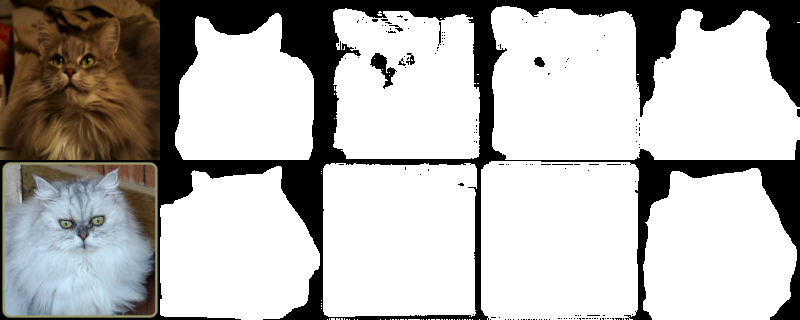

In [13]:
from IPython.display import display

# Иллюстрация худших случаев из файла: расчёт из предыдущей ячейки повторять не нужно.
print("Столбцы: изображение, эталон, маска SAM, маска после корректора, маска baseline.")
print("Строки: Maine_Coon_222.jpg, Persian_99.jpg.")
display(Image.open(ARTIFACTS / "correction_failures.png"))


### Задание 11. Творческий бонус: второй тип точки

*Вес: 1 дополнительный балл.*

**Постановка.** Качество SAM зависит от выбора положительной точки.

Выполните следующие действия:
1. Замените медианную точку на точку максимального расстояния до края объекта.
2. На тех же test-изображениях сравните IoU с исходной подсказкой.

**Результат.** bonus_points.json с парными IoU для двух стратегий.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Как определяется медианная точка (point_from_mask):
1. Берём координаты всех пикселей объекта.
2. Находим отдельно медиану всех x и медиану всех y. Получается точка [x, y].
3. Если она попала в фон, берём ближайший к ней пиксель объекта.

Как определяется точка максимального расстояния (inner_point_from_mask):
1. Для каждого пикселя объекта считаем расстояние до ближайшего пикселя фона. Это делает функция distance_transform_edt, а край кадра тоже считается границей объекта.
2. Выбираем пиксель с наибольшим расстоянием.

In [14]:
def edge_distance(mask):
    """Расстояние от каждого пикселя объекта до ближайшего пикселя фона; край кадра тоже считается краем объекта."""
    padded = np.pad(np.asarray(mask, dtype=bool), 1)  # рамка из фона: объект, обрезанный кадром, не «уходит» за него
    return ndimage.distance_transform_edt(padded)[1:-1, 1:-1]


def inner_point_from_mask(mask):
    """Положительная точка [x, y] — пиксель объекта, максимально удалённый от его края.

    Моделирует разметчика, который кликает в самую «толстую» часть объекта, а не в его геометрическую середину.
    Точка детерминирована: при равных расстояниях берётся первый пиксель в порядке обхода по строкам.
    """
    distance = edge_distance(mask)
    y, x = np.unravel_index(int(distance.argmax()), distance.shape)
    return [int(x), int(y)]


# Вторая стратегия сравнивается с исходной (медианной) на тех же test-изображениях и по тем же эталонам.
# Результаты медианной точки берутся из сравнения point и box, заново считается только новая точка.
bonus_rows = []
for pos in range(len(eval_ds)):
    image, gt = eval_ds[pos]
    median_row = per_image[pos]["point"]
    median_point, inner_point = median_row["prompt"], inner_point_from_mask(gt)
    mask, score = predict_sam(image, point=inner_point)
    distance = edge_distance(gt)
    bonus_rows.append({"position": pos, "dataset_index": eval_idx[pos], "file": per_image[pos]["file"],
                       "median": {"prompt": median_point, "iou": median_row["iou"], "sam_score": median_row["sam_score"],
                                  "edge_distance": round(float(distance[median_point[1], median_point[0]]), 1)},
                       "inner": {"prompt": inner_point, "iou": round(iou(mask, gt), 4), "sam_score": round(score, 4),
                                 "edge_distance": round(float(distance[inner_point[1], inner_point[0]]), 1)}})

STRATEGIES = ("median", "inner")
point_ious = {name: np.array([row[name]["iou"] for row in bonus_rows]) for name in STRATEGIES}
bonus_summary = {name: {
    "mean_iou": round(float(point_ious[name].mean()), 4),
    "median_iou": round(float(np.median(point_ious[name])), 4),
    "share_iou_below_0.5": round(float((point_ious[name] < 0.5).mean()), 4),
    "mean_edge_distance_px": round(float(np.mean([row[name]["edge_distance"] for row in bonus_rows])), 1),
} for name in STRATEGIES}
bonus_summary["paired_inner_minus_median"] = paired_summary(point_ious["inner"], point_ious["median"], ("inner", "median"))
bonus_summary["same_point_share"] = round(float(np.mean([row["median"]["prompt"] == row["inner"]["prompt"] for row in bonus_rows])), 4)

bonus_points = {
    "split": "Oxford-IIIT Pet test",
    "n_images": len(bonus_rows),
    "sam_checkpoint": SAM_CHECKPOINT,
    "strategies": {"median": "point_from_mask: медиана координат пикселей объекта",
                   "inner": "inner_point_from_mask: пиксель объекта, максимально удалённый от его края"},
    "fast_dev_run": FAST_DEV_RUN,
    "summary": bonus_summary,
    "per_image": bonus_rows,
}
(ARTIFACTS / "bonus_points.json").write_text(json.dumps(bonus_points, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(bonus_summary, ensure_ascii=False, indent=2))
_m = np.zeros((9, 11), dtype=bool)
_m[1:8, 2:9] = True  # квадрат 7x7: самый удалённый от края пиксель — его центр
check(inner_point_from_mask(_m) == [5, 4], "на ручном примере точка совпадает с центром квадрата")
check(all(eval_ds[row["position"]][1][row["inner"]["prompt"][1], row["inner"]["prompt"][0]] for row in bonus_rows[:20]),
      "новая точка лежит на объекте")
check(all(row["inner"]["edge_distance"] >= row["median"]["edge_distance"] for row in bonus_rows),
      "новая точка не ближе к краю объекта, чем медианная")
check([row["dataset_index"] for row in bonus_rows] == dataset_manifest["eval_indices"], "обе стратегии оценены на одних test-индексах")
check((ARTIFACTS / "bonus_points.json").exists(), "bonus_points.json сохранён")

{
  "median": {
    "mean_iou": 0.6872,
    "median_iou": 0.7844,
    "share_iou_below_0.5": 0.145,
    "mean_edge_distance_px": 85.9
  },
  "inner": {
    "mean_iou": 0.6838,
    "median_iou": 0.7879,
    "share_iou_below_0.5": 0.165,
    "mean_edge_distance_px": 102.9
  },
  "paired_inner_minus_median": {
    "mean_diff": -0.0034,
    "ci95": [
      -0.0409,
      0.0338
    ],
    "inner_better_share": 0.5,
    "median_better_share": 0.475
  },
  "same_point_share": 0.0
}
✔ на ручном примере точка совпадает с центром квадрата
✔ новая точка лежит на объекте
✔ новая точка не ближе к краю объекта, чем медианная
✔ обе стратегии оценены на одних test-индексах
✔ bonus_points.json сохранён


## Анализ результатов

Все числа ниже получены в полном режиме (`FAST_DEV_RUN=False`) на реальных данных Oxford-IIIT Pet и взяты из файлов в `artifacts/lab3`.

Все методы оценены на одних и тех же 200 изображениях test, зафиксированных в `dataset_manifest.json`, и по одним эталонным маскам. IoU считается по каждому изображению и усредняется. Интервалы в квадратных скобках — 95 %-й бутстреп средней разности по изображениям.

### Бюджет

| Этап | Модель и данные | Вычисления |
|---|---|---|
| SAM, zero-shot | ViT-B (`facebook/sam-vit-base`), 93,74 млн параметров, веса заморожены | Только inference (применение уже готовое модели): 68 с на 200 изображений с двумя подсказками |
| Baseline | LRASPP-MobileNetV3-Large, 3,22 млн параметров; 3312 изображений trainval для обучения, 368 для контроля; 256×256 | 6 эпох, AdamW, lr 5e-4, weight decay 1e-4, батч 32, mixed precision; около 24 с на эпоху, около 3 минут всего |
| Корректор | Свёрточная голова, 28 961 параметр; 200 изображений trainval для обучения, 40 для контроля; 256×256 | Маски SAM для 240 изображений — 76 с; 40 эпох, AdamW, lr 2e-3, батч 16 — 37 с; оставлены веса эпохи 37, лучшей на контроле |
| Оценка | 200 изображений test из 3669, длинная сторона не более 512 px | seed 42, по одному запуску на модель |

Encoder SAM обрабатывает изображение за 287 мс, ответ на подсказку при готовом embedding занимает 25–43 мс. Поэтому embedding считается один раз на изображение и используется для обеих подсказок.

### Эталон и подсказки

В разметке три класса: питомец, фон и пограничная лента. SAM выдаёт объект и фон, поэтому эталон бинарный: объект — питомец вместе с лентой. Посторонние области класса «граница», не связанные с питомцем, отбрасываются, иначе рамка по маске растягивается на весь кадр.

Box и point вычисляются из эталонной маски и моделируют идеального разметчика: рамка вплотную к объекту, клик в медиану его пикселей. Измеренное качество — оценка сверху для работы с неточными подсказками.

### Point и box

| Показатель | Box | Point |
|---|---|---|
| Средний IoU | 0,796 | 0,687 |
| Медианный IoU | 0,812 | 0,784 |
| Минимальный IoU | 0,085 | 0,003 |
| Доля изображений с IoU ниже 0,5 | 1,5 % | 14,5 % |
| Средняя собственная оценка SAM | 0,987 | 0,949 |
| Площадь маски к площади эталона | 0,869 | 0,741 |

Box даёт IoU в среднем на 0,108 выше [0,071; 0,147] и лучше на 68 % изображений. Медианы различаются всего на 0,03: на типичном изображении подсказки почти равноценны, а разницу в среднем создают провалы точки. В 28 из 29 таких провалов площадь маски меньше половины эталона, то есть по одному клику SAM выделил часть питомца.

Собственная оценка SAM завышена относительно измеренного IoU и слабо с ним связана: корреляция 0,33 для box и 0,55 для point. Принимать маску только по этой оценке нельзя.

### SAM, baseline и корректор

| Показатель | SAM, box | Baseline | SAM + корректор |
|---|---|---|---|
| Средний IoU | 0,796 | 0,902 | 0,889 |
| Медианный IoU | 0,812 | 0,925 | 0,921 |
| Минимальный IoU | 0,085 | 0,230 | 0,153 |
| Доля изображений с IoU ниже 0,5 | 1,5 % | 0,5 % | 1,0 % |
| Площадь маски к площади эталона | 0,869 | 0,988 | 0,999 |

Парные разности среднего IoU:

- baseline − SAM: +0,107 [0,091; 0,124], baseline лучше на 95,5 % изображений;
- корректор − SAM: +0,093 [0,087; 0,100], корректор лучше на 99 % изображений;
- baseline − корректор: +0,013 [−0,004; 0,032], интервал включает ноль.

Корректор закрыл 0,093 из 0,107 разрыва между SAM и baseline. По числу изображений, где метод лучший из трёх, корректор впереди: 108 против 92 у baseline; исходная маска SAM не лучшая ни разу.

Корректор почти только расширяет маску: добавленные пиксели составляют в среднем 13,3 % площади эталона, убранные — 0,3 %. Площадь маски при этом приходит от 0,869 эталона к 0,999. Это согласуется с тем, что основное расхождение SAM с разметкой — пограничная лента: SAM проводит контур по видимому краю животного, а эталон включает полосу вокруг него.

Доля масок, требующих существенной правки (IoU ниже порога):

| Порог IoU | SAM, box | SAM + корректор |
|---|---|---|
| 0,75 | 23,0 % | 8,5 % |
| 0,80 | 43,5 % | 12,5 % |
| 0,85 | 75,5 % | 19,5 % |
| 0,90 | 94,5 % | 36,5 % |

Основным принят порог 0,85. При любом из четырёх порогов корректор сокращает долю таких масок в 2,6–3,9 раза.

Оценки на контрольных частях trainval согласуются с test: baseline — 0,899 против 0,902; прирост от корректора — +0,069 на 40 контрольных изображениях против +0,093 на test.

### Ошибки моделей

**Грубые промахи SAM корректор не исправляет.** На трёх изображениях IoU маски SAM по box ниже 0,5: `chihuahua_42.jpg` (индекс 1021, 0,085), `japanese_chin_2.jpg` (1704, 0,086), `wheaten_terrier_66.jpg` (3531, 0,434). После корректора — 0,154, 0,153 и 0,588. Поле зрения головы — 31 пиксель, и ошибку такого масштаба она не видит. Baseline на этих изображениях даёт 0,92–0,95. Причины самих промахов SAM не разбирались.

**Отрицательный перенос редок и мал.** Корректор снизил IoU на 2 изображениях из 200: `Maine_Coon_222.jpg` (индекс 1982, 0,768 → 0,754) и `Persian_99.jpg` (2379, 0,800 → 0,789). Ни одна маска с IoU не ниже 0,85 не опустилась ниже порога. В обоих случаях кот занимает почти весь кадр, и маска SAM уже больше эталона (1,21 и 1,18 его площади). Корректор расширил её ещё (1,31 и 1,25): выученная поправка рассчитана на типичную ошибку SAM и вредит при противоположной. Оба случая показаны на `correction_failures.png`.

**Методы ошибаются на разных изображениях.** На `Bombay_58.jpg` (индекс 743) baseline даёт 0,230, тогда как SAM — 0,822, а корректор — 0,925. Baseline находит объект сам и может ошибиться с тем, где он; SAM получает это из подсказки.

### Вторая стратегия точки

Контролируемое сравнение: меняется только положение точки, изображения, модель и эталон те же.

| Показатель | Медиана координат | Максимум расстояния до края |
|---|---|---|
| Средний IoU | 0,687 | 0,684 |
| Медианный IoU | 0,784 | 0,788 |
| Доля изображений с IoU ниже 0,5 | 14,5 % | 16,5 % |
| Среднее расстояние точки до края, px | 86 | 103 |

Разность среднего IoU равна −0,003 [−0,041; 0,034] и от нуля неотличима. Точки при этом разные на всех 200 изображениях, и результаты расходятся сильно: новая точка исправила 12 провалов медианной и создала 16 новых, на 17 изображениях провалились обе. Перенос точки вглубь объекта меняет, на каких изображениях SAM ошибается, но не как часто.

### Ограничения

- **Подсказки взяты из эталона.** Это идеальный разметчик; с реальными рамками и кликами качество SAM будет не выше измеренного. Baseline подсказок не получает, поэтому сравнение с ним не симметрично.
- **Разные бюджеты разметки.** Baseline обучен на 3312 изображениях, корректор — на 200, SAM — ни на одном изображении этого набора.
- **Бинарное правило задаёт потолок для SAM.** IoU без учёта пограничной ленты в артефактах не измерен, поэтому доля разрыва, приходящаяся на соглашение разметки, оценена косвенно — по изменению площади масок.
- **Один запуск на модель.** Интервалы отражают разброс по изображениям, но не разброс между запусками обучения.
- **200 изображений test из 3669.** Редкие ошибки представлены единицами случаев: три промаха SAM, два случая отрицательного переноса.
- **Эпоха корректора выбрана по 40 изображениям**, и IoU на контроле между эпохами колебался.
- **Порог существенной правки выбран нами.** Доли приведены для четырёх порогов; число взаимодействий до целевого IoU не измерялось — каждая маска получена по одной подсказке.
- **Корректор обучен и проверен только на масках SAM по box** и только с SAM ViT-B.
- **Baseline и корректор работают при 256 px**, их маски растягиваются до исходного размера.
- **Smoke-режим** (`FAST_DEV_RUN=True`) использует 8 изображений test, baseline на 58 изображениях за одну эпоху и корректор на 8 изображениях за две эпохи. Он проверяет только исполнимость кода, его показатели в отчёт не входят.

## Выводы

1. **Zero-shot SAM выделяет питомца без обучения на этом наборе, но расходится с его разметкой.** С box из эталона средний IoU на 200 изображениях test равен 0,796, грубых промахов (IoU ниже 0,5) — 1,5 % (`prompt_results.json`). Маски SAM в среднем занимают 0,869 площади эталона: модель проводит контур по видимому краю, а эталон включает пограничную ленту.

2. **Box надёжнее точки, а не точнее на типичном изображении.** Средний IoU с box выше на 0,108 [0,071; 0,147], но медианы почти равны: 0,812 и 0,784. Разницу создают провалы точки — 14,5 % изображений против 1,5 %; почти во всех из них SAM выделил часть питомца (`prompt_results.json`). Одна точка не сообщает, какой уровень объекта нужен.

3. **Положение точки эту неоднозначность не снимает.** Точка, максимально удалённая от края, даёт тот же средний IoU, что и медианная: разность −0,003 [−0,041; 0,034]. Она исправляет 12 провалов и создаёт 16 новых (`bonus_points.json`).

4. **Обученный baseline выше SAM на 0,107 IoU, и основная часть этого разрыва — соглашение разметки.** LRASPP, обученный на 3312 изображениях, достигает 0,902 (`supervised_comparison.json`). Корректор с 28 961 параметром, обученный на 200 изображениях, поднимает маски SAM до 0,889 — на 0,093 [0,087; 0,100] (`adapted_comparison.json`). Он почти только добавляет пиксели вдоль контура, и площадь масок приходит к 0,999 эталона. Столь малая голова с полем зрения 31 пиксель вряд ли способна заново находить объект; она переносит границу туда, где её проводит разметка.

5. **После коррекции SAM статистически не отличается от baseline по среднему IoU.** Разность baseline − корректор равна +0,013 [−0,004; 0,032]; корректор лучший из трёх методов на 108 изображениях, baseline — на 92 (`correction_failures.json`). Доля масок, требующих существенной правки при пороге 0,85, падает с 75,5 % до 19,5 % (`adapted_comparison.json`).

6. **Отрицательный перенос есть, но редок и мал.** Корректор снизил IoU на 2 изображениях из 200, оба раза примерно на 0,01, и ни одну приемлемую маску не сделал неприемлемой. Механизм один: маска SAM уже была больше эталона, а корректор её ещё расширил (`correction_failures.json`, `correction_failures.png`).

7. **Грубые промахи остаются за пределами коррекции, а методы дополняют друг друга.** Три маски SAM с IoU ниже 0,5 корректор поднимает лишь до 0,15–0,59, тогда как baseline даёт на них 0,92–0,95. Обратный пример — `Bombay_58.jpg`, где baseline даёт 0,230, а SAM с корректором — 0,925 (`correction_failures.json`).

**Практический итог.** Для ускорения разметки под конкретный набор достаточно zero-shot SAM с box и небольшой головы, обученной на 200 размеченных изображениях: на этих данных это дало средний IoU, сопоставимый с моделью, обученной на всём наборе. Условие — для каждого изображения есть рамка; здесь она взята из эталона.

**Что стоит проверить дальше.** Измерить IoU без учёта пограничной ленты, чтобы оценить вклад соглашения разметки напрямую. Заменить box из эталона на рамки с шумом или от детектора. Измерить число кликов до целевого IoU, добавляя отрицательные точки. Повторить обучение baseline и корректора с несколькими seed. Проверить корректор на масках SAM по точке и выяснить причины трёх грубых промахов SAM по box.